[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR/blob/main/colab_tuning.ipynb)

# Part A: tuning the classifiers

Two settings, tuned on val only, on 10% of the labels: **CNN-3 fine-tuning** and the **ResNet-18 linear probe**. The other classifiers (the CNN-3 linear probe, ResNet-18 fine-tuning, the supervised baselines) keep the settings in `config.py`. The DAE's own hyperparameters were tuned in search 1 and 2.

Three grids, one after the other. In each, **one hyperparameter at a time**, with 5 values, and the others fixed at what was chosen so far:

- **Grid 1, learning:** learning rate, the head's learning rate (fine-tuning only: in the linear probe only the head trains), batch size.
- **Grid 2, regularization:** dropout, augmentation, label smoothing.
- **Grid 3, optimizer:** the optimizer (AdamW, Adam, NAdam, RAdam, SGD with Nesterov momentum; SGD with a 10 times larger learning rate, its usual range), and its weight decay. Weight decay comes right after the optimizer because Adam and AdamW differ only in how they apply it. The encoders keep the activation they were pretrained with: another one would change the function their weights learned.

The best value of each, by val accuracy, is kept for the next one. Every run uses seed 42; the seeds come after the tuning, in `colab_final.ipynb`. Every run: up to 50 rounds (a round is as many images as 100% of the labels), stopped after 3 rounds with no better val accuracy (`--patience 3`; the final runs use 5). `--tune`: no test set. The choice of a setting goes to `midterm_runs/tuning_choice.json` when all its grids are done, so `colab_final.ipynb` never reads half a tuning.

On one L4 runtime: CNN-3 about 3 hours, ResNet-18 about 4.5 hours (its pretraining first).

## Setup
Downloads the repository (or pulls the latest code), installs it and checks the GPU.

In [1]:
import os

REPO = "/content/Representation-Learning-Midterm-DAE-SimCLR"
if not os.path.exists(REPO):
    !git clone https://github.com/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR.git {REPO}
os.chdir(REPO)
!git pull
!git log --oneline -1

Already up to date.
a1d5b67 (HEAD -> main, origin/main, origin/HEAD) Tune only CNN-3 fine-tuning and the ResNet-18 linear probe, with full grids and --patience 3; tune() starts from the defaults and saves its choice at the end


In [2]:
%pip install -q -r requirements.txt

import torch
assert torch.cuda.is_available(), "No GPU. Runtime → Change runtime type → L4 GPU, then rerun this cell."
print(torch.cuda.get_device_name(0), "|", os.cpu_count(), "CPU cores")

NVIDIA L4 | 12 CPU cores


## Drive
Every run writes to `midterm_runs`, next to the earlier runs. The tuning runs have `tune` in their folder name.

In [3]:
from google.colab import drive

drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע"
OUT = f"{DRIVE_DIR}/midterm_runs"
assert os.path.isdir(OUT), f"no folder {OUT}"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## TensorBoard
Filter the runs with `tune`, then *Toggle all runs*. The `epoch` section has train and val by round, the TEXT tab each run's `run_info`.

In [4]:
%load_ext tensorboard
%tensorboard --logdir "{OUT}"

Reusing TensorBoard on port 6007 (pid 106562), started 0:06:47 ago. (Use '!kill 106562' to kill it.)

<IPython.core.display.Javascript object>

## The search
`tune` runs the hyperparameters of one setting in the order given, 5 values each, and keeps the best. Runs that finished before are not trained again (train.py finds their folder), so after a disconnect, run the same cell again: every setting starts from the same values, so it repeats the same runs, and the finished ones are skipped.

In [5]:
import importlib
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

VALUES = {
    "lr": [3e-5, 1e-4, 3e-4, 1e-3, 3e-3],
    "head_lr_mult": [1, 3, 10, 30, 100],
    "batch_size": [32, 64, 128, 256, 512],
    "wd": [0, 1e-5, 1e-4, 5e-4, 1e-3],
    "dropout": [0, 0.1, 0.25, 0.4, 0.5],
    "augment": ["none", "flip", "crop", "crop_rotate", "crop_jitter"],
    "label_smoothing": [0, 0.05, 0.1, 0.15, 0.2],
    "optimizer": ["adamw", "adam", "nadam", "radam", "sgd"],
}
GRID_1 = ["lr", "head_lr_mult", "batch_size"]  # learning; the head's lr: fine-tuning only
GRID_2 = ["dropout", "augment", "label_smoothing"]  # regularization
GRID_3 = ["optimizer", "wd"]  # optimizer
SGD_LR = 10  # SGD's learning rate, as a multiple of the Adam ones
DEFAULTS = {"head_lr_mult": 1, "batch_size": 256, "wd": 0, "dropout": 0, "augment": "flip", "label_smoothing": 0.1,
            "optimizer": "adamw"}
CHOICE_FILE = f"{OUT}/tuning_choice.json"
R = "--backbone resnet18 --decoder resnet18"  # the ResNet-18 DAE


def folder_of(flags):
    """The run folder train.py uses for these flags (run_info.folder_name)."""
    import config, utils, run_info
    for module in (config, utils, run_info):
        importlib.reload(module)
    sys.argv = ["train.py", *flags.split(), "--output_dir", OUT]
    return f"{OUT}/{run_info.folder_name(utils.parse_args().mode)}"


def train(flags):
    """One run of train.py, and its val numbers."""
    !python train.py {flags} --output_dir "{OUT}"
    with open(f"{folder_of(flags)}/results.json") as f:
        return json.load(f)


def tune(setting, base, lr, order):
    """Tune setting one hyperparameter at a time, from the defaults; save and return its choice."""
    choice = {"lr": lr, **DEFAULTS}
    for name in order:
        rows = []
        adam_lr = float(f"{choice['lr'] / SGD_LR:.3g}") if choice["optimizer"] == "sgd" else choice["lr"]
        for value in VALUES[name]:
            trial = {**choice, name: value}
            if name == "optimizer":  # each optimizer with its own learning-rate range
                trial["lr"] = float(f"{adam_lr * SGD_LR:.3g}") if value == "sgd" else adam_lr
            flags = f"{base} --label_fraction 0.1 --max_rounds 50 --patience 3 --tune " + " ".join(f"--{k} {v}" for k, v in trial.items())
            results = train(flags)
            rows.append({name: value, **{k: results.get(f"val_{k}") for k in ("accuracy", "top5_accuracy", "calibration_error", "loss")}})
        table = pd.DataFrame(rows)
        choice[name] = VALUES[name][int(table["accuracy"].idxmax())]  # the value itself, not a numpy number
        if name == "optimizer":
            choice["lr"] = float(f"{adam_lr * SGD_LR:.3g}") if choice[name] == "sgd" else adam_lr
        print(f"{setting}, {name}: chose {choice[name]}")
        display(table.round(4))
        fig, ax = plt.subplots(1, 2, figsize=(9, 3))
        for axis, metric in zip(ax, ("accuracy", "calibration_error")):
            axis.plot([str(v) for v in table[name]], table[metric], marker="o")
            axis.set_xlabel(name)
            axis.set_title(f"val {metric}")
        fig.suptitle(setting)
        plt.show()
    choices = json.load(open(CHOICE_FILE)) if os.path.exists(CHOICE_FILE) else {}
    choices[setting] = choice  # only now: the file holds finished tunings only
    with open(CHOICE_FILE, "w") as f:
        json.dump(choices, f, indent=1)
    return choice

## CNN-3
The final CNN-3 DAE first (`colab_final.ipynb` then skips it). Then fine-tuning, all three grids.

In [6]:
!python train.py --mode pretrain --output_dir "{OUT}"

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
DenoisingAutoEncoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=16384, out_features=256, b

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
EncoderClassifier(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=16384, out_features=256, bias

,lr,accuracy,top5_accuracy,calibration_error,loss
0,0.0000,0.0734,0.2038,0.0255,4.9344
1,0.0001,0.0753,0.2072,0.0592,5.0274
2,0.0003,0.0805,0.2181,0.0732,5.0185
3,0.0010,0.0677,0.1906,0.1909,5.7374
4,0.0030,0.0526,0.1549,0.1397,5.6098


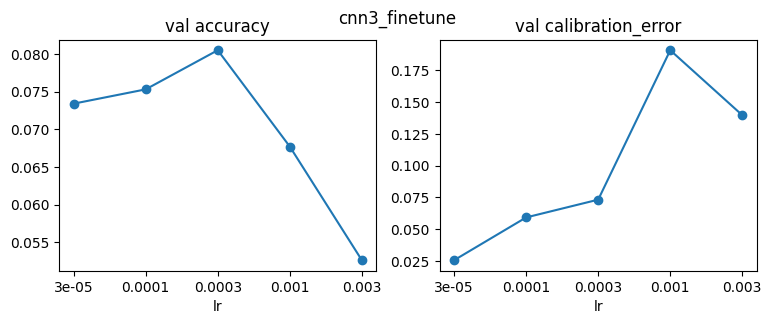

Seed set to 42
date23112026_time031211_CNN3_tune_finetune_DAE_on_TinyImageNet_10pct_lr0.0003_seed42 already finished; its results are in /content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע/midterm_runs/date23112026_time031211_CNN3_tune_finetune_DAE_on_TinyImageNet_10pct_lr0.0003_seed42/results.json

Validation results (search or tuning run):
  val_loss 5.0185, val_accuracy 0.0805, val_auroc 0.7733, val_calibration_error 0.0732, val_f1 0.0717, val_precision 0.0749, val_recall 0.0805, val_top5_accuracy 0.2181
Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batche

,head_lr_mult,accuracy,top5_accuracy,calibration_error,loss
0,1,0.0805,0.2181,0.0732,5.0185
1,3,0.0809,0.2178,0.0928,5.0958
2,10,0.0716,0.2033,0.1430,5.3953
3,30,0.0679,0.1846,0.1869,5.7674
4,100,0.0623,0.1699,0.2152,6.0632


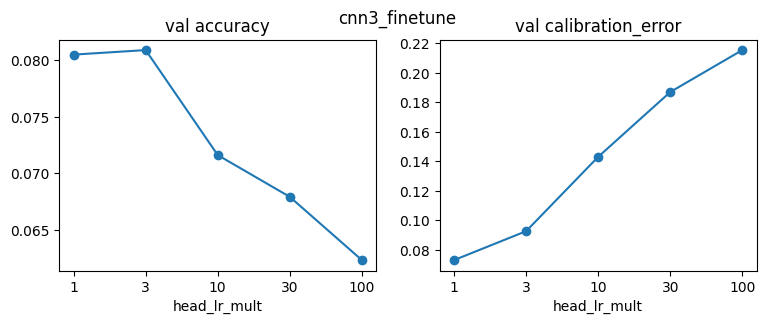

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
EncoderClassifier(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=16384, out_features=256, bias

,batch_size,accuracy,top5_accuracy,calibration_error,loss
0,32,0.0646,0.1845,0.1952,5.8072
1,64,0.0713,0.1969,0.2019,5.8109
2,128,0.0758,0.2063,0.1638,5.5076
3,256,0.0809,0.2178,0.0928,5.0958
4,512,0.0800,0.2204,0.0591,4.9772


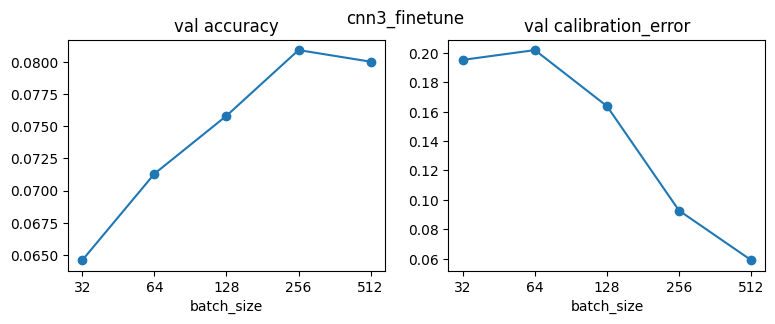

Seed set to 42
date23112026_time031712_CNN3_tune_finetune_DAE_on_TinyImageNet_10pct_lr0.0003_hm3_seed42 already finished; its results are in /content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע/midterm_runs/date23112026_time031712_CNN3_tune_finetune_DAE_on_TinyImageNet_10pct_lr0.0003_hm3_seed42/results.json

Validation results (search or tuning run):
  val_loss 5.0958, val_accuracy 0.0809, val_auroc 0.7725, val_calibration_error 0.0928, val_f1 0.0737, val_precision 0.0763, val_recall 0.0809, val_top5_accuracy 0.2178
Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of th

,dropout,accuracy,top5_accuracy,calibration_error,loss
0,0.00,0.0809,0.2178,0.0928,5.0958
1,0.10,0.0841,0.2235,0.0702,4.9870
2,0.25,0.0868,0.2318,0.0405,4.8522
3,0.40,0.0921,0.2419,0.0110,4.7453
4,0.50,0.0958,0.2464,0.0167,4.6991


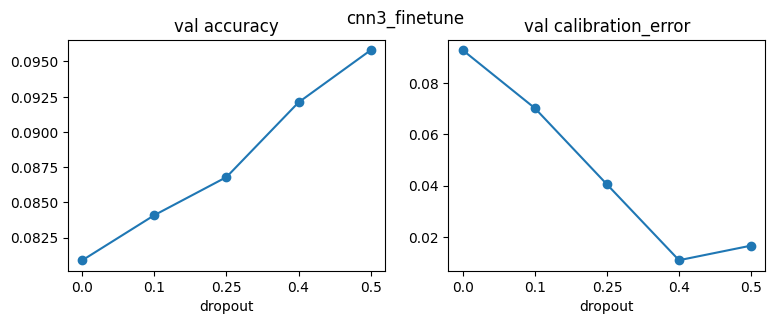

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
EncoderClassifier(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=16384, out_features=256, bias

,augment,accuracy,top5_accuracy,calibration_error,loss
0,none,0.0742,0.2107,0.0441,4.9345
1,flip,0.0958,0.2464,0.0167,4.6991
2,crop,0.1279,0.3031,0.0887,4.7728
3,crop_rotate,0.1338,0.3128,0.1101,4.8280
4,crop_jitter,0.1343,0.3130,0.0697,4.6875


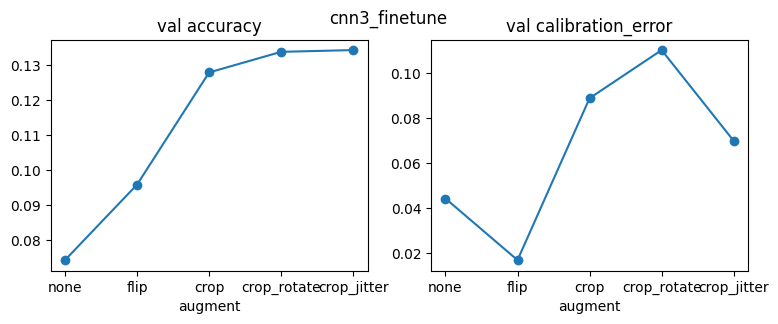

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
EncoderClassifier(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=16384, out_features=256, bias

,label_smoothing,accuracy,top5_accuracy,calibration_error,loss
0,0.00,0.1368,0.3159,0.1361,4.6151
1,0.05,0.1354,0.3134,0.1000,4.6441
2,0.10,0.1343,0.3130,0.0697,4.6875
3,0.15,0.1337,0.3131,0.0434,4.7374
4,0.20,0.1326,0.3094,0.0215,4.7901


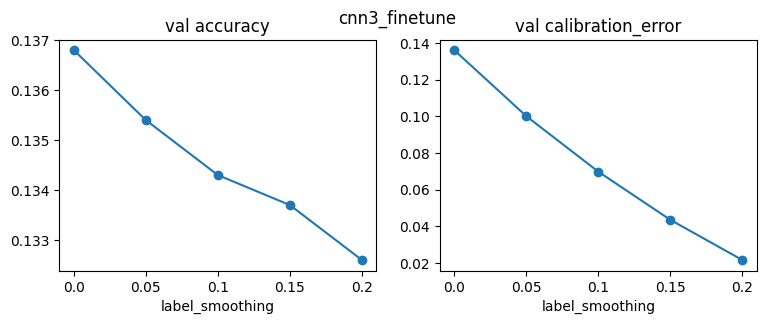

Seed set to 42
date23112026_time035635_CNN3_tune_finetune_DAE_on_TinyImageNet_10pct_lr0.0003_hm3_do0.5_aug-crop_jitter_ls0_seed42 already finished; its results are in /content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע/midterm_runs/date23112026_time035635_CNN3_tune_finetune_DAE_on_TinyImageNet_10pct_lr0.0003_hm3_do0.5_aug-crop_jitter_ls0_seed42/results.json

Validation results (search or tuning run):
  val_loss 4.6151, val_accuracy 0.1368, val_auroc 0.8314, val_calibration_error 0.1361, val_f1 0.1270, val_precision 0.1245, val_recall 0.1368, val_top5_accuracy 0.3159
Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(li

,optimizer,accuracy,top5_accuracy,calibration_error,loss
0,adamw,0.1368,0.3159,0.1361,4.6151
1,adam,0.1366,0.3159,0.1363,4.6152
2,nadam,0.1325,0.3110,0.1388,4.6478
3,radam,0.1321,0.3070,0.1001,4.5049
4,sgd,0.1599,0.3596,0.1599,4.4450


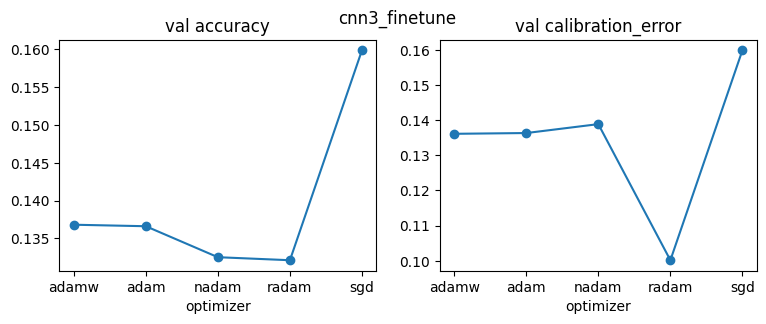

Seed set to 42
date23112026_time043355_CNN3_tune_finetune_DAE_on_TinyImageNet_10pct_lr0.003_hm3_do0.5_aug-crop_jitter_ls0_opt-sgd_seed42 already finished; its results are in /content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע/midterm_runs/date23112026_time043355_CNN3_tune_finetune_DAE_on_TinyImageNet_10pct_lr0.003_hm3_do0.5_aug-crop_jitter_ls0_opt-sgd_seed42/results.json

Validation results (search or tuning run):
  val_loss 4.4450, val_accuracy 0.1599, val_auroc 0.8556, val_calibration_error 0.1599, val_f1 0.1521, val_precision 0.1511, val_recall 0.1599, val_top5_accuracy 0.3596
Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platfor

,wd,accuracy,top5_accuracy,calibration_error,loss
0,0.0000,0.1599,0.3596,0.1599,4.4450
1,0.0000,0.1601,0.3596,0.1595,4.4443
2,0.0001,0.1594,0.3596,0.1591,4.4376
3,0.0005,0.1584,0.3599,0.1560,4.4131
4,0.0010,0.1565,0.3604,0.1699,4.4667


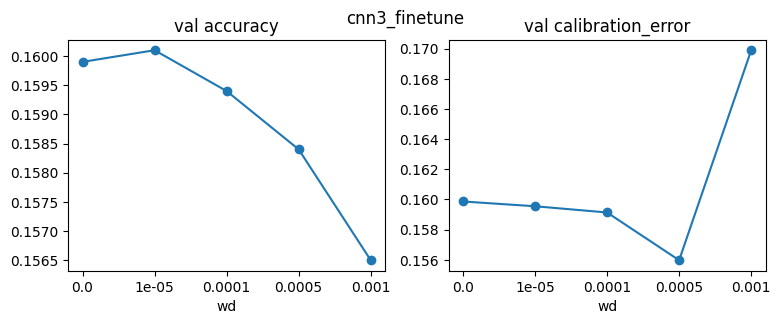

{'lr': 0.003,
 'head_lr_mult': 3,
 'batch_size': 256,
 'wd': 1e-05,
 'dropout': 0.5,
 'augment': 'crop_jitter',
 'label_smoothing': 0,
 'optimizer': 'sgd'}

In [7]:
tune("cnn3_finetune", "--mode finetune --encoder dae", 1e-4, GRID_1 + GRID_2 + GRID_3)

## ResNet-18
The ResNet-18 DAE first, as in `colab_final.ipynb` (30 epochs; about 2.5 hours). Then the linear probe, all three grids except the head's learning rate: only the head trains.

In [8]:
!python train.py --mode pretrain {R} --num_epochs 30 --output_dir "{OUT}"

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
DenoisingAutoEncoder(
  (encoder): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): Identity()
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Co

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
EncoderClassifier(
  (encoder): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): Identity()
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2

,lr,accuracy,top5_accuracy,calibration_error,loss
0,0.0000,0.0531,0.1557,0.0241,5.0027
1,0.0001,0.0544,0.1615,0.0163,4.9864
2,0.0003,0.0563,0.1643,0.0098,5.0291
3,0.0010,0.0560,0.1638,0.0094,5.0169
4,0.0030,0.0531,0.1624,0.0240,5.0766


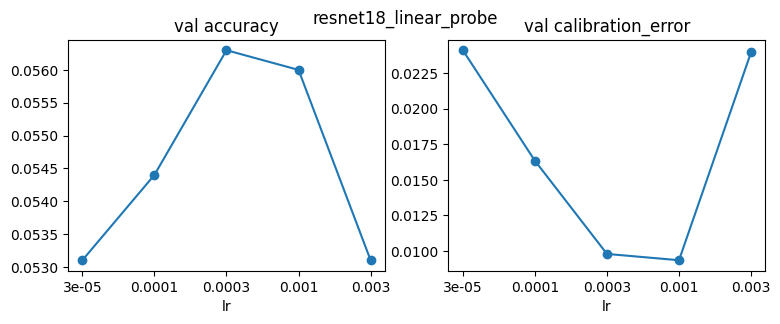

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
EncoderClassifier(
  (encoder): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): Identity()
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2

,batch_size,accuracy,top5_accuracy,calibration_error,loss
0,32,0.0566,0.1650,0.0079,5.0215
1,64,0.0564,0.1626,0.0095,5.0200
2,128,0.0568,0.1632,0.0086,4.9930
3,256,0.0563,0.1643,0.0098,5.0291
4,512,0.0553,0.1630,0.0111,4.9883


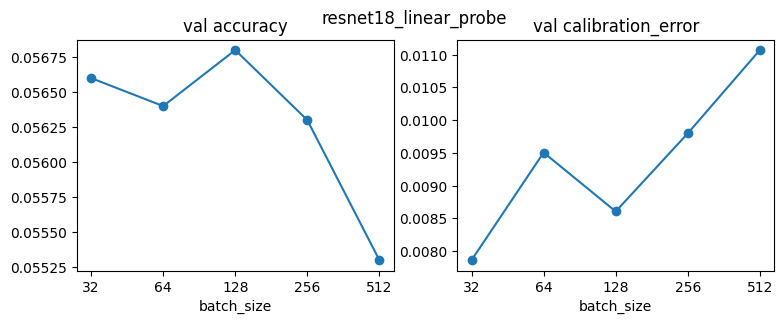

Seed set to 42
date23112026_time080943_ResNet18_tune_linear_probe_DAE_on_TinyImageNet_lr0.0003_bs128_seed42 already finished; its results are in /content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע/midterm_runs/date23112026_time080943_ResNet18_tune_linear_probe_DAE_on_TinyImageNet_lr0.0003_bs128_seed42/results.json

Validation results (search or tuning run):
  val_loss 4.9930, val_accuracy 0.0568, val_auroc 0.7155, val_calibration_error 0.0086, val_f1 0.0455, val_precision 0.0430, val_recall 0.0568, val_top5_accuracy 0.1632
Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 10

,dropout,accuracy,top5_accuracy,calibration_error,loss
0,0.00,0.0568,0.1632,0.0086,4.9930
1,0.10,0.0563,0.1630,0.0047,5.0004
2,0.25,0.0561,0.1648,0.0145,4.9827
3,0.40,0.0564,0.1633,0.0145,4.9797
4,0.50,0.0562,0.1633,0.0180,4.9780


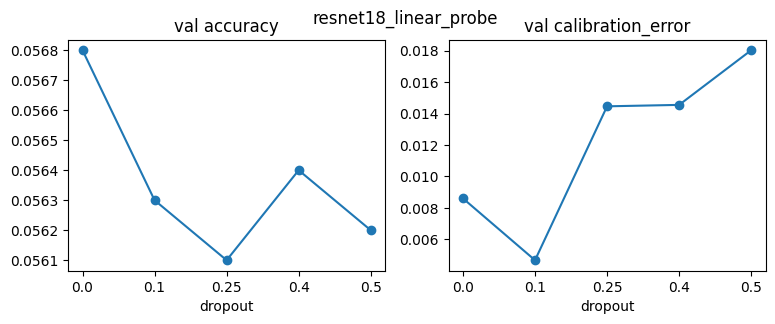

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
EncoderClassifier(
  (encoder): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): Identity()
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2

,augment,accuracy,top5_accuracy,calibration_error,loss
0,none,0.0482,0.1462,0.0075,5.0732
1,flip,0.0568,0.1632,0.0086,4.9930
2,crop,0.0620,0.1724,0.0088,4.9821
3,crop_rotate,0.0563,0.1707,0.0080,4.9729
4,crop_jitter,0.0622,0.1743,0.0087,4.9869


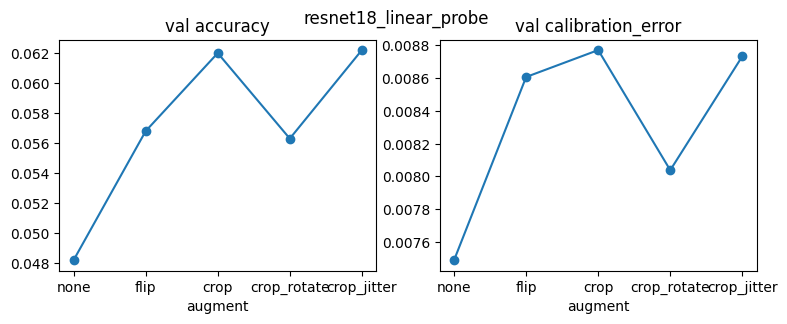

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
EncoderClassifier(
  (encoder): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): Identity()
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2

,label_smoothing,accuracy,top5_accuracy,calibration_error,loss
0,0.00,0.0610,0.1734,0.0186,4.8948
1,0.05,0.0615,0.1736,0.0122,4.9395
2,0.10,0.0622,0.1743,0.0087,4.9869
3,0.15,0.0622,0.1747,0.0061,5.0253
4,0.20,0.0625,0.1744,0.0097,5.0558


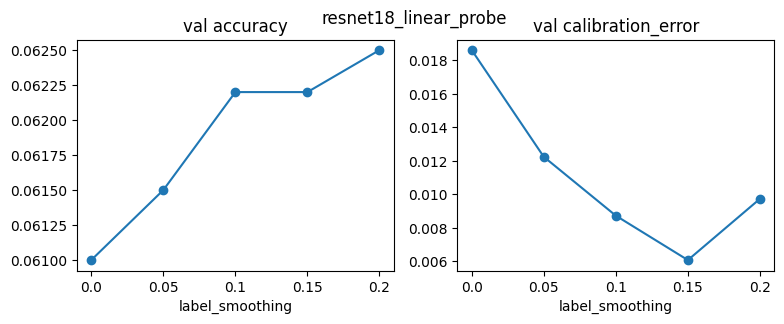

Seed set to 42
date23112026_time095611_ResNet18_tune_linear_probe_DAE_on_TinyImageNet_lr0.0003_bs128_aug-crop_jitter_ls0.2_seed42 already finished; its results are in /content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע/midterm_runs/date23112026_time095611_ResNet18_tune_linear_probe_DAE_on_TinyImageNet_lr0.0003_bs128_aug-crop_jitter_ls0.2_seed42/results.json

Validation results (search or tuning run):
  val_loss 5.0558, val_accuracy 0.0625, val_auroc 0.7337, val_calibration_error 0.0097, val_f1 0.0489, val_precision 0.0529, val_recall 0.0625, val_top5_accuracy 0.1744
Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(li

,optimizer,accuracy,top5_accuracy,calibration_error,loss
0,adamw,0.0625,0.1744,0.0097,5.0558
1,adam,0.0625,0.1744,0.0097,5.0558
2,nadam,0.0625,0.1742,0.0097,5.0558
3,radam,0.0633,0.1734,0.0076,5.0678
4,sgd,0.0530,0.1593,0.0231,5.0478


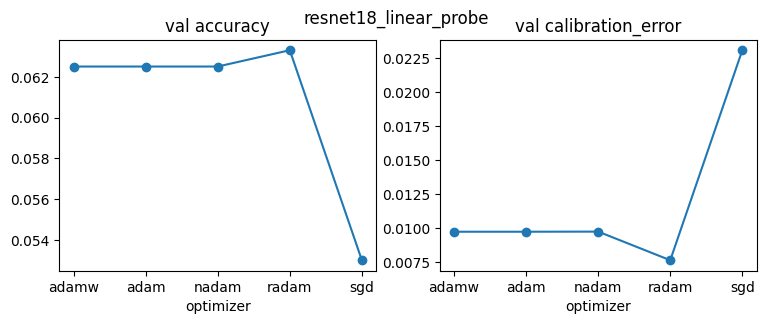

Seed set to 42
date23112026_time102807_ResNet18_tune_linear_probe_DAE_on_TinyImageNet_lr0.0003_bs128_aug-crop_jitter_ls0.2_opt-radam_seed42 already finished; its results are in /content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע/midterm_runs/date23112026_time102807_ResNet18_tune_linear_probe_DAE_on_TinyImageNet_lr0.0003_bs128_aug-crop_jitter_ls0.2_opt-radam_seed42/results.json

Validation results (search or tuning run):
  val_loss 5.0678, val_accuracy 0.0633, val_auroc 0.7351, val_calibration_error 0.0076, val_f1 0.0513, val_precision 0.0541, val_recall 0.0633, val_top5_accuracy 0.1734
Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments p

,wd,accuracy,top5_accuracy,calibration_error,loss
0,0.0000,0.0633,0.1734,0.0076,5.0678
1,0.0000,0.0624,0.1745,0.0099,5.0556
2,0.0001,0.0636,0.1735,0.0118,5.0486
3,0.0005,0.0592,0.1688,0.0219,5.0249
4,0.0010,0.0592,0.1677,0.0277,5.0247


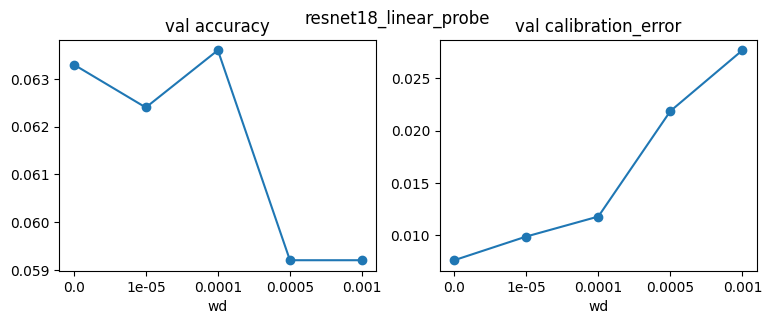

{'lr': 0.0003,
 'head_lr_mult': 1,
 'batch_size': 128,
 'wd': 0.0001,
 'dropout': 0,
 'augment': 'crop_jitter',
 'label_smoothing': 0.2,
 'optimizer': 'radam'}

In [9]:
tune("resnet18_linear_probe", f"--mode linear_probe --encoder dae {R}", 1e-3, [h for h in GRID_1 + GRID_2 + GRID_3 if h != "head_lr_mult"])

## The choices
What every setting chose. `colab_final.ipynb` uses them.

In [10]:
pd.DataFrame(json.load(open(CHOICE_FILE))).T

,lr,head_lr_mult,batch_size,wd,dropout,augment,label_smoothing,optimizer
cnn3_finetune,0.003,3,256,0.00001,0.5,crop_jitter,0,sgd
resnet18_linear_probe,0.0003,1,128,0.0001,0,crop_jitter,0.2,radam
